# Day 38: Veda Technology Business & Service Analytics

**Dataset:** the cleaned Veda Technology tables saved on Day 35
(`datasets/veda_business/cleaned/`)

This notebook is the last of four days in the Veda Technology Business & Service Analytics
project. It covers the predictive analysis (a demand forecast and a model that predicts
which service inquiries will convert), the business recommendations, and the figures behind
the executive-level analytics report.

## 1. Import Libraries and Load the Cleaned Tables

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, mean_absolute_error, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CLEAN_DIR = Path("../datasets/veda_business/cleaned")

visits = pd.read_csv(CLEAN_DIR / "website_visits_cleaned.csv", parse_dates=["visit_date"])
applications = pd.read_csv(CLEAN_DIR / "internship_applications_cleaned.csv", parse_dates=["application_date"])
training = pd.read_csv(CLEAN_DIR / "training_enrollments_cleaned.csv", parse_dates=["enrollment_date"])
it_inquiries = pd.read_csv(CLEAN_DIR / "it_service_inquiries_cleaned.csv", parse_dates=["inquiry_date"])
digital_inquiries = pd.read_csv(CLEAN_DIR / "digital_service_inquiries_cleaned.csv", parse_dates=["inquiry_date"])
requests = pd.read_csv(CLEAN_DIR / "service_requests_cleaned.csv", parse_dates=["request_date"])
marketing = pd.read_csv(CLEAN_DIR / "marketing_campaigns_cleaned.csv", parse_dates=["month"])

print("Loaded", sum(len(t) for t in [visits, applications, training, it_inquiries, digital_inquiries, requests, marketing]), "rows in 7 tables")

Loaded 34060 rows in 7 tables


## 2. Predictive Analysis 1: Demand Forecasting

Forecasting is limited here by the length of the data: the dataset covers **one year**
(October 2025 to September 2026). That is enough to learn the weekly pattern, but not enough
to learn the yearly seasonal pattern, because every month has been seen only once. This
section shows both sides: a backtest on the daily website traffic, and a planning forecast
for the next quarter that is honest about what one year can and cannot support.

**The daily website visits series**

In [2]:
daily_visits = visits.groupby("visit_date").size().asfreq("D", fill_value=0).rename("visits")
series = daily_visits.to_frame()
series["day_number"] = np.arange(len(series))
series["weekday"] = series.index.dayofweek

weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print("Days in the series:", len(series))
print("Average visits per day by weekday:")
print(series.groupby("weekday")["visits"].mean().round(1).rename(dict(enumerate(weekday_names))))

Days in the series: 365
Average visits per day by weekday:
weekday
Monday       73.0
Tuesday      74.9
Wednesday    74.3
Thursday     74.3
Friday       74.3
Saturday     45.1
Sunday       44.1
Name: visits, dtype: float64


**A backtest: train on October to June, forecast July to September**

Two simple models are compared. The **weekday average** repeats the typical visits for each
weekday over the last 28 training days. The **trend and weekday regression** is a linear
regression on the day number (the trend) and the day of the week. Both are tested on the
last 92 days, which the models never saw.

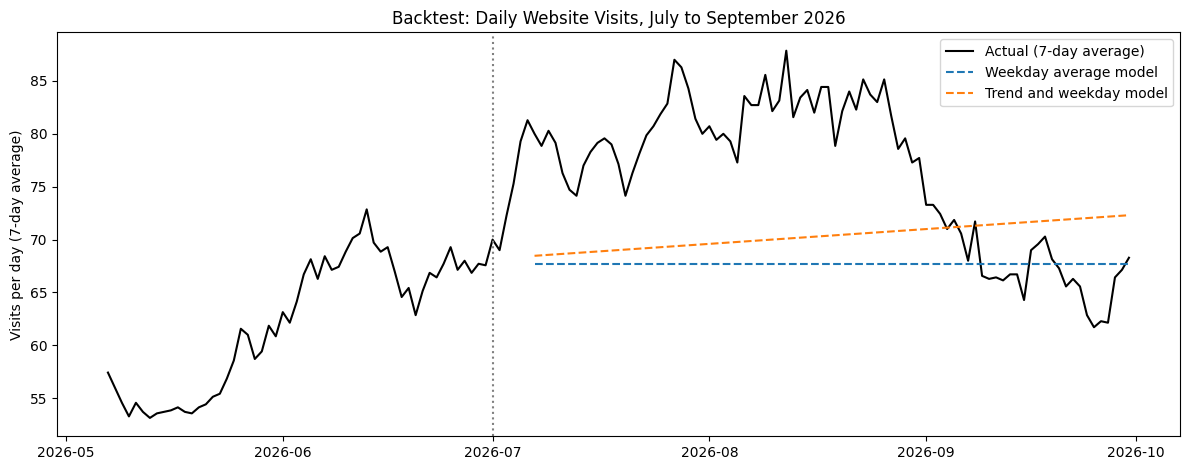

                   MAE (visits per day)  MAPE (%)  \
weekday_average                   11.82     14.63   
trend_and_weekday                 11.17     14.14   

                   Total over 92 days vs. actual (%)  
weekday_average                               -11.37  
trend_and_weekday                              -7.82  

            actual  weekday_average  trend_and_weekday  \
visit_date                                               
2026-07       2498           2128.0             2164.0   
2026-08       2499           2059.0             2149.0   
2026-09       2036           2046.0             2171.0   

            trend_and_weekday_error_pct  
visit_date                               
2026-07                           -13.4  
2026-08                           -14.0  
2026-09                             6.6  


In [3]:
split_date = pd.Timestamp("2026-07-01")
train, test = series[series.index < split_date], series[series.index >= split_date]

# Model 1: the weekday average of the last 28 training days
weekday_profile = train.tail(28).groupby("weekday")["visits"].mean()
weekday_forecast = test["weekday"].map(weekday_profile)


# Model 2: linear regression on the day number (trend) and weekday
def design(frame):
    weekday_dummies = pd.get_dummies(frame["weekday"], prefix="wd", drop_first=True, dtype=int)
    return pd.concat([frame[["day_number"]], weekday_dummies], axis=1)


trend_model = LinearRegression().fit(design(train), train["visits"])
trend_forecast = pd.Series(trend_model.predict(design(test)), index=test.index)

backtest = pd.DataFrame({"actual": test["visits"], "weekday_average": weekday_forecast, "trend_and_weekday": trend_forecast})

forecast_metrics = pd.DataFrame({
    model: {
        "MAE (visits per day)": mean_absolute_error(backtest["actual"], backtest[model]),
        "MAPE (%)": (abs(backtest["actual"] - backtest[model]) / backtest["actual"]).mean() * 100,
        "Total over 92 days vs. actual (%)": (backtest[model].sum() / backtest["actual"].sum() - 1) * 100,
    }
    for model in ["weekday_average", "trend_and_weekday"]
}).T.round(2)

monthly_backtest = backtest.groupby(backtest.index.to_period("M")).sum().round(0)
monthly_backtest["trend_and_weekday_error_pct"] = ((monthly_backtest["trend_and_weekday"] / monthly_backtest["actual"] - 1) * 100).round(1)

plt.figure(figsize=(12, 4.8))
recent = series[series.index >= "2026-05-01"]["visits"].rolling(7).mean()
plt.plot(recent.index, recent, label="Actual (7-day average)", color="black")
plt.plot(backtest.index, backtest["weekday_average"].rolling(7).mean(), label="Weekday average model", linestyle="--")
plt.plot(backtest.index, backtest["trend_and_weekday"].rolling(7).mean(), label="Trend and weekday model", linestyle="--")
plt.axvline(split_date, color="gray", linestyle=":")
plt.ylabel("Visits per day (7-day average)")
plt.title("Backtest: Daily Website Visits, July to September 2026")
plt.legend()
plt.tight_layout()
plt.show()

print(forecast_metrics)
print()
print(monthly_backtest)

**Observation:** both models learn the weekly rhythm but miss the summer peak. The weekday
average is off by 11.8 visits a day (14.6%) and the trend and weekday regression by 11.2
(14.1%), on days that average 76 visits. The monthly view shows why: the regression
underestimates July by 13.4% and August by 14.0%, the two busiest months, and overestimates
September by 6.6%. Nothing in the October to June data hints at a July peak, because the
seasonal pattern appears only once in this dataset, so no model trained on it could have
foreseen the peak. Forecasting seasonal swings takes at least two years of history. This is
also why the planning forecast below uses last year's same months and scenarios instead of a
fitted model.

**A planning forecast for October to December 2026**

With a single year of history, the best available method is a **seasonal naive** forecast:
the demand of the same month last year, scaled by an assumed growth rate. The growth rate
itself cannot be estimated from one year, because growth and seasonality are mixed together,
so three **scenarios** are shown instead of a single prediction.

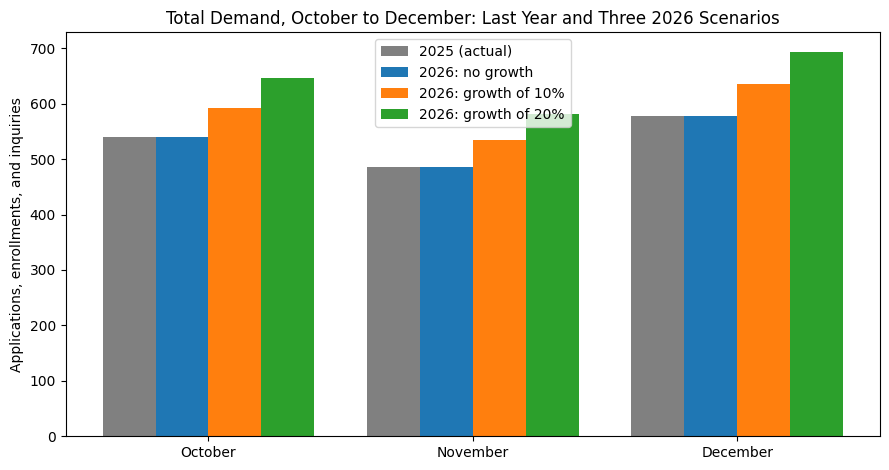

,Q4 2025 (actual),Q4 2026: No growth,Q4 2026: Growth of 10%,Q4 2026: Growth of 20%
Internship applications,630,630,693,756
Training enrollments,386,386,425,463
IT inquiries,262,262,288,314
Digital inquiries,324,324,356,389
Total demand,1602,1602,1762,1922
Website visits,4804,4804,5284,5765


In [4]:
def monthly_count(table, date_column, label):
    return table.groupby(table[date_column].dt.to_period("M")).size().rename(label)


monthly_demand = pd.concat([
    monthly_count(applications, "application_date", "Internship applications"),
    monthly_count(training, "enrollment_date", "Training enrollments"),
    monthly_count(it_inquiries, "inquiry_date", "IT inquiries"),
    monthly_count(digital_inquiries, "inquiry_date", "Digital inquiries"),
], axis=1)
monthly_demand["Total demand"] = monthly_demand.sum(axis=1)
monthly_demand["Website visits"] = monthly_count(visits, "visit_date", "Website visits")

q4_2025 = monthly_demand.loc["2025-10":"2025-12"]
scenarios = {"No growth": 0.0, "Growth of 10%": 0.10, "Growth of 20%": 0.20}

q4_plan = pd.DataFrame({"Q4 2025 (actual)": q4_2025.sum()})
for name, growth in scenarios.items():
    q4_plan[f"Q4 2026: {name}"] = (q4_2025.sum() * (1 + growth)).round(0)
q4_plan = q4_plan.astype(int)

labels = ["October", "November", "December"]
x = np.arange(3)
plt.figure(figsize=(9, 4.8))
plt.bar(x - 0.3, q4_2025["Total demand"].to_numpy(), 0.2, label="2025 (actual)", color="gray")
for i, (name, growth) in enumerate(scenarios.items()):
    plt.bar(x - 0.1 + 0.2 * i, (q4_2025["Total demand"] * (1 + growth)).round(0).to_numpy(), 0.2, label=f"2026: {name.lower()}")
plt.xticks(x, labels)
plt.ylabel("Applications, enrollments, and inquiries")
plt.title("Total Demand, October to December: Last Year and Three 2026 Scenarios")
plt.legend()
plt.tight_layout()
plt.show()

q4_plan

**Observation:** in Q4 2025 the four business lines recorded 1,602 applications,
enrollments, and inquiries (539, 485, and 578 in October, November, and December), and the
website had 4,804 visits. The planning range for Q4 2026 runs from 1,602 with no growth,
through 1,762 with 10% growth, to 1,922 with 20% growth. Q4 is slightly quieter than the
average month of the year (a demand index of about 94), with a weak November. The growth
rates are assumptions, so this is a planning range and not a prediction, and it should be
replaced by a fitted forecast once a second year of data exists.

## 3. Predictive Analysis 2: Which Service Inquiries Will Convert?

Could a model that scores each new inquiry by its chance of becoming a deal help the sales
team follow up with the most promising ones first (**lead scoring**)? This section tests
that question honestly, including the possibility that the answer is "not very well". The IT
and digital inquiries are combined, and the model is trained only on inquiries that have an
outcome (`Converted` or `Lost`). Inquiries still `In Progress` have no outcome yet, so they
cannot be used for training, but they can be scored afterward.

The predictors are the service line, service type, client type, channel, the budget, and the
response time (as a number, and as two flags for replies within 4 hours and after more than
24 hours, the cutoffs that mattered on Day 36). The response time is known once the first
reply is sent, so it is available when the model is used. The status and the deal value are
never used as predictors, since they reveal the outcome.

**Preparing the data**

In [5]:
inquiries = pd.concat([
    it_inquiries.assign(service_line="IT services"), digital_inquiries.assign(service_line="Digital services"),
], ignore_index=True)
inquiries["log_budget"] = np.log1p(inquiries["budget_inr"])
inquiries["log_response_hours"] = np.log1p(inquiries["response_time_hours"])
inquiries["fast_reply"] = (inquiries["response_time_hours"] <= 4).astype(int)
inquiries["slow_reply"] = (inquiries["response_time_hours"] > 24).astype(int)

closed = inquiries[inquiries["status"] != "In Progress"].copy()
closed["converted"] = (closed["status"] == "Converted").astype(int)
still_open = inquiries[inquiries["status"] == "In Progress"].copy()

numeric_features = ["log_budget", "log_response_hours", "fast_reply", "slow_reply"]
categorical_features = ["service_line", "service_type", "client_type", "channel"]
features = numeric_features + categorical_features

X_train, X_test, y_train, y_test = train_test_split(
    closed[features], closed["converted"], test_size=0.2, random_state=42, stratify=closed["converted"]
)

print("Inquiries with an outcome:", len(closed), "| still in progress:", len(still_open))
print(f"Conversion rate among inquiries with an outcome: {closed['converted'].mean() * 100:.1f}%")
print("Training set:", len(X_train), "| Test set:", len(X_test))

Inquiries with an outcome: 1796 | still in progress: 604
Conversion rate among inquiries with an outcome: 59.2%
Training set: 1436 | Test set: 360


**Training and comparing the models**

A logistic regression is compared with a random forest and with a baseline that always
predicts the most common outcome. The ROC AUC is the main measure (0.5 is random guessing,
1.0 is perfect).

In [6]:
def build_preprocessing():
    return ColumnTransformer([
        ("numbers", StandardScaler(), numeric_features),
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])


baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
logistic = make_pipeline(build_preprocessing(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
forest = make_pipeline(
    build_preprocessing(), RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=42, n_jobs=-1)
).fit(X_train, y_train)


def classification_metrics(model, columns=None):
    X_eval = X_test if columns is None else X_test[columns]
    predicted = model.predict(X_eval)
    probability = model.predict_proba(X_eval)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, predicted), "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0), "F1": f1_score(y_test, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probability),
    }


# A deliberately simple model that only knows how fast the reply was
reply_columns = ["fast_reply", "slow_reply"]
reply_only = LogisticRegression().fit(X_train[reply_columns], y_train)

model_results = pd.DataFrame({
    "Baseline (most common outcome)": classification_metrics(baseline),
    "Logistic regression (all predictors)": classification_metrics(logistic),
    "Logistic regression (reply speed only)": classification_metrics(reply_only, reply_columns),
    "Random forest (all predictors)": classification_metrics(forest),
}).T.round(3)

# A single test set of this size is noisy, so the AUC is also cross-validated 5 times over
cv_splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
cv_auc = cross_val_score(
    make_pipeline(build_preprocessing(), LogisticRegression(max_iter=1000)), X_train, y_train, cv=cv_splits, scoring="roc_auc"
)
print(f"Logistic regression, repeated 5-fold cross-validated ROC AUC on the training set: mean {cv_auc.mean():.3f} (std {cv_auc.std():.3f})")
model_results

Logistic regression, repeated 5-fold cross-validated ROC AUC on the training set: mean 0.585 (std 0.026)


,Accuracy,Precision,Recall,F1,ROC AUC
Baseline (most common outcome),0.592,0.592,1.000,0.743,0.500
Logistic regression (all predictors),0.597,0.620,0.826,0.708,0.574
Logistic regression (reply speed only),0.603,0.600,0.986,0.746,0.585
Random forest (all predictors),0.578,0.598,0.873,0.710,0.566


**What drives conversion? The logistic regression coefficients**

Numeric predictors are standardized, so their coefficients show the effect of one standard
deviation. Category coefficients are relative to the other categories of the same column. A
positive coefficient raises the chance of conversion.

In [7]:
feature_names = logistic[0].get_feature_names_out()
coefficients = pd.Series(logistic[-1].coef_[0], index=feature_names).sort_values(ascending=False).round(3)
coefficients.index = [name.split("__", 1)[1] for name in coefficients.index]

print("Strongest positive effects")
print(coefficients.head(6))
print("\nStrongest negative effects")
print(coefficients.tail(6))

Strongest positive effects
channel_Referral               0.639
service_type_Cybersecurity     0.395
fast_reply                     0.328
client_type_SME                0.315
service_type_Cloud & DevOps    0.135
client_type_Individual         0.127
dtype: float64

Strongest negative effects
service_type_SEO                        -0.131
client_type_Individual / Freelancer     -0.155
slow_reply                              -0.159
channel_Organic Search                  -0.227
channel_Email                           -0.260
service_type_IT Support & Maintenance   -0.353
dtype: float64


**Observation:** of the 1,796 inquiries with an outcome, 59.2% converted, so always
predicting `Converted` is right 59.2% of the time. The logistic regression reaches 59.7%
accuracy and a ROC AUC of 0.57 on the test set, and the repeated cross-validation averages
0.58 (std 0.03), so the model is only slightly better than random guessing (0.5). The random
forest does no better (0.57), and a model that only knows whether the reply was fast or slow
does just as well as the full model (0.58), so the extra predictors add almost nothing. The
coefficients show why: only a few stand out. Referral inquiries (+0.64) and fast replies
(+0.33) raise the chance of conversion and slow replies lower it (-0.16), which agrees with
Day 36, while the other coefficients are small and probably noise. In this dataset,
conversion depends mostly on how fast Veda Technology replies and where the inquiry came
from, not on who the client is or what service they want, so a more complex model has
nothing more to learn.

**Does the model rank inquiries well? A lift analysis on the test set**

The test inquiries are sorted by predicted probability and split into five equal groups. If
the model ranks well, the top group should convert far more often than the bottom group.

Overall conversion rate in the test set: 59.2%
Lift of the top 20%: 1.06 times the overall rate


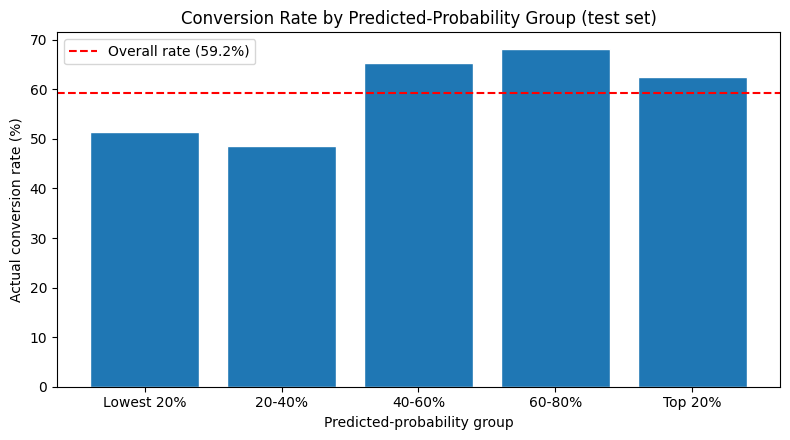

,inquiries,conversions,conversion_rate_pct,share_of_all_conversions_pct
score_group,,,,
Lowest 20%,72,37,51.4,17.4
20-40%,72,35,48.6,16.4
40-60%,72,47,65.3,22.1
60-80%,72,49,68.1,23.0
Top 20%,72,45,62.5,21.1


In [8]:
test_scores = X_test.copy()
test_scores["converted"] = y_test.to_numpy()
test_scores["probability"] = logistic.predict_proba(X_test)[:, 1]
test_scores["score_group"] = pd.qcut(
    test_scores["probability"].rank(method="first"), 5, labels=["Lowest 20%", "20-40%", "40-60%", "60-80%", "Top 20%"]
)

lift_table = test_scores.groupby("score_group", observed=True).agg(
    inquiries=("converted", "count"), conversions=("converted", "sum"), conversion_rate_pct=("converted", "mean"),
)
lift_table["conversion_rate_pct"] *= 100
lift_table["share_of_all_conversions_pct"] = lift_table["conversions"] / lift_table["conversions"].sum() * 100
lift_table = lift_table.round(1)

base_rate = y_test.mean() * 100
top_group = lift_table.loc["Top 20%"]
print(f"Overall conversion rate in the test set: {base_rate:.1f}%")
print(f"Lift of the top 20%: {top_group['conversion_rate_pct'] / base_rate:.2f} times the overall rate")

plt.figure(figsize=(8, 4.5))
plt.bar(lift_table.index.astype(str), lift_table["conversion_rate_pct"], edgecolor="white")
plt.axhline(base_rate, color="red", linestyle="--", label=f"Overall rate ({base_rate:.1f}%)")
plt.ylabel("Actual conversion rate (%)")
plt.xlabel("Predicted-probability group")
plt.title("Conversion Rate by Predicted-Probability Group (test set)")
plt.legend()
plt.tight_layout()
plt.show()

lift_table

**Observation:** a useful model would convert much more often in the top group than in the
bottom one, rising steadily across the groups. Here the pattern is irregular: the top 20%
converts at 62.5% against 51.4% for the bottom 20%, but the two middle groups do better than
the top (65.3% and 68.1%), and the top group captures only 21.1% of all conversions, about
what a random 20% of inquiries would give. The lift of the top group is only 1.06 times the
overall rate of 59.2%. In other words, the model cannot reliably rank individual inquiries,
so it should not be used to decide whom to call first.

**Using the model on inquiries that are still in progress**

The trained model scores the inquiries that have no outcome yet. Multiplying the probability
by the budget (and by the typical share of the budget that ends up as the deal value) gives
an expected value that can be used to decide whom to follow up with first.

In [9]:
deal_ratio = (closed.loc[closed["converted"] == 1, "deal_value_inr"] / closed.loc[closed["converted"] == 1, "budget_inr"]).mean()

still_open["probability"] = logistic.predict_proba(still_open[features])[:, 1]
still_open["expected_value_inr"] = still_open["probability"] * still_open["budget_inr"] * deal_ratio

open_summary = pd.Series({
    "Inquiries still in progress": len(still_open),
    "Expected conversions": still_open["probability"].sum(),
    "Expected deal value (INR million)": still_open["expected_value_inr"].sum() / 1e6,
    "Lowest predicted probability": still_open["probability"].min(),
    "Highest predicted probability": still_open["probability"].max(),
    "Share of expected value in the top 10% of inquiries (%)": still_open.nlargest(int(len(still_open) * 0.1), "expected_value_inr")["expected_value_inr"].sum() / still_open["expected_value_inr"].sum() * 100,
    "Correlation of expected value with budget": still_open["expected_value_inr"].corr(still_open["budget_inr"]),
}).round(2)

priority_list = still_open.nlargest(8, "expected_value_inr")[
    ["inquiry_id", "service_line", "service_type", "client_type", "channel", "budget_inr", "response_time_hours", "probability", "expected_value_inr"]
].round({"probability": 3, "expected_value_inr": 0})

print(f"Typical deal value as a share of the budget: {deal_ratio * 100:.1f}%\n")
print(open_summary)
print("\nTop 8 inquiries to follow up first")
print(priority_list.to_string(index=False))

Typical deal value as a share of the budget: 88.3%

Inquiries still in progress                                604.00
Expected conversions                                       347.99
Expected deal value (INR million)                           78.53
Lowest predicted probability                                 0.25
Highest predicted probability                                0.83
Share of expected value in the top 10% of inquiries (%)     49.93
Correlation of expected value with budget                    0.97
dtype: float64

Top 8 inquiries to follow up first
inquiry_id service_line                service_type client_type        channel  budget_inr  response_time_hours  probability  expected_value_inr
   IT00639  IT services               Cybersecurity  Enterprise         Direct     3310000                  3.5        0.765           2237276.0
   IT00454  IT services               Cybersecurity  Enterprise          Email     2795000                  5.9        0.569           1403705.0


**Observation:** the model gives the 604 inquiries still in progress a probability between
0.25 and 0.83, an expected 348 conversions, and INR 78.5 million in deal value. Because the
probabilities differ little compared with how widely the budgets vary, the expected value is
almost the same as the budget (correlation 0.97), so the priority list above is in practice
a ranking of the biggest budgets, led by Enterprise IT inquiries, and the top 10% of
inquiries hold 50% of the expected value. Focusing follow-up on the few large inquiries is
still sensible, but that advice comes from the budgets and not from the model, and the
expected totals should be treated as rough, given how weak the model is.

## 4. Business Recommendations

Each recommendation below is tied to a finding from the four days of analysis, with a rough
estimate of the possible impact calculated from the data. The impacts are **illustrative
upper-end scenarios, not promises**: they assume the relationships in the (simulated) data
are causal and keep working at a larger scale, which is the first thing to test in real
life.

**Scenario calculations**

In [10]:
# 1. Rebalance the marketing budget (Paid Ads and Social Media toward Referral and Email)
channel_marketing = marketing.groupby("channel").agg(spend=("spend_inr", "sum"), leads=("leads", "sum"))
weak = channel_marketing.loc[["Paid Ads", "Social Media"]]
strong = channel_marketing.loc[["Referral", "Email"]]
SHIFT_SHARE, EFFICIENCY_KEPT = 0.15, 0.5

moved_spend = weak["spend"].sum() * SHIFT_SHARE
leads_lost = moved_spend / (weak["spend"].sum() / weak["leads"].sum())
leads_gained = moved_spend / (strong["spend"].sum() / strong["leads"].sum()) * EFFICIENCY_KEPT
net_new_leads = leads_gained - leads_lost
marketing_scenario = {
    "moved_spend_k": moved_spend / 1000, "leads_lost": leads_lost, "leads_gained": leads_gained,
    "net_new_leads": net_new_leads, "uplift_pct": net_new_leads / channel_marketing["leads"].sum() * 100,
    "weak_cpl": weak["spend"].sum() / weak["leads"].sum(), "strong_cpl": strong["spend"].sum() / strong["leads"].sum(),
}

# 2. Answer every inquiry within 4 hours
def response_scenario(table):
    data = table.copy()
    data["converted"] = (data["status"] == "Converted").astype(int)
    data["band"] = pd.cut(data["response_time_hours"], bins=[0, 4, 24, np.inf], labels=["fast", "mid", "slow"])
    rates = data.groupby("band", observed=True)["converted"].agg(["count", "mean"])
    extra = sum(rates.loc[b, "count"] * max(rates.loc["fast", "mean"] - rates.loc[b, "mean"], 0) for b in ["mid", "slow"])
    avg_deal = data.loc[data["converted"] == 1, "deal_value_inr"].mean()
    return {"fast_rate": rates.loc["fast", "mean"] * 100, "slower_share": (1 - rates.loc["fast", "count"] / len(data)) * 100,
            "current_conversions": data["converted"].sum(), "extra_conversions": extra, "extra_value": extra * avg_deal}


it_response, digital_response = response_scenario(it_inquiries), response_scenario(digital_inquiries)
response_extra = it_response["extra_conversions"] + digital_response["extra_conversions"]
response_value = it_response["extra_value"] + digital_response["extra_value"]
response_pct = response_extra / (it_response["current_conversions"] + digital_response["current_conversions"]) * 100

# 3. Close part of the mobile conversion gap
device_rates = visits.groupby("device").agg(visits=("visit_id", "count"), rate=("converted", "mean"))
mobile, desktop = device_rates.loc["Mobile"], device_rates.loc["Desktop"]
MOBILE_TARGET = 0.75
mobile_extra = mobile["visits"] * max(MOBILE_TARGET * desktop["rate"] - mobile["rate"], 0)
mobile_pct = mobile_extra / visits["converted"].sum() * 100

# 4. Fast-track the Large inquiries (budget over INR 500K)
inquiries["converted"] = (inquiries["status"] == "Converted").astype(int)
large = inquiries[inquiries["budget_inr"] >= 500000]
large_avg_deal = large.loc[large["converted"] == 1, "deal_value_inr"].mean()
LARGE_GAIN_POINTS = 5
large_extra_value = len(large) * (LARGE_GAIN_POINTS / 100) * large_avg_deal

# 5. Early warning for low attendance in training
below_60 = (training["attendance_pct"] < 60).sum()
band_60_69 = training[(training["attendance_pct"] >= 60) & (training["attendance_pct"] < 70)]["completed"].mean()
RECOVERED_SHARE = 0.5
training_extra = below_60 * RECOVERED_SHARE * band_60_69
training_pct = training_extra / training["completed"].sum() * 100
offline_gap = (training[training["mode"] == "Offline"]["completed"].mean() - training[training["mode"] == "Online"]["completed"].mean()) * 100

# 6. Customer service: billing queries, escalations, and critical requests
closed_requests = requests[requests["status"] != "Open"]
billing_hours = closed_requests[closed_requests["request_type"] == "Billing Query"]["resolution_time_hours"].mean()
other_hours = closed_requests[closed_requests["request_type"] != "Billing Query"]["resolution_time_hours"].mean()
escalated_csat = requests[requests["status"] == "Escalated"]["satisfaction_rating"].mean()
resolved_csat = requests[requests["status"] == "Resolved"]["satisfaction_rating"].mean()
critical = closed_requests[closed_requests["priority"] == "Critical"]
critical_sla = (critical["resolution_time_hours"] <= 8).mean() * 100

# Supporting figures quoted in the recommendations
weak_spend_share = weak["spend"].sum() / channel_marketing["spend"].sum() * 100
mobile_share = mobile["visits"] / len(visits) * 100
large_inquiry_share = len(large) / len(inquiries) * 100
large_value_share = large["deal_value_inr"].sum() / inquiries["deal_value_inr"].sum() * 100
all_services = pd.concat([
    training["program"].value_counts(), it_inquiries["service_type"].value_counts(),
    digital_inquiries["service_type"].value_counts(), applications["domain"].value_counts(),
])
cyber_rank = int((all_services > all_services["Cybersecurity"]).sum() + 1)

# 7. Seasonal peaks by business line
peak_months = monthly_demand.drop(columns=["Total demand", "Website visits"]).idxmax().map(lambda p: p.strftime("%B"))

print(pd.Series(marketing_scenario).round(1).to_string())
print(f"\nResponse scenario: +{response_extra:.0f} conversions ({response_pct:.1f}%), +INR {response_value / 1e6:.1f} million")
print(f"Mobile scenario: +{mobile_extra:.0f} conversions ({mobile_pct:.1f}%)")
print(f"Large inquiries: {len(large)} inquiries, average deal INR {large_avg_deal:,.0f}, +{LARGE_GAIN_POINTS} points = INR {large_extra_value / 1e6:.1f} million")
print(f"Training: {below_60} students below 60% attendance, {training_extra:.0f} extra completions ({training_pct:.1f}%), offline gap {offline_gap:.1f} points")
print(f"Requests: billing {billing_hours:.1f}h vs {other_hours:.1f}h, escalated CSAT {escalated_csat:.2f} vs {resolved_csat:.2f}, critical SLA {critical_sla:.1f}%")
print("Peak months:", peak_months.to_dict())

moved_spend_k     181.9
leads_lost       1163.2
leads_gained     4703.6
net_new_leads    3540.3
uplift_pct         17.5
weak_cpl          156.4
strong_cpl         19.3

Response scenario: +234 conversions (22.0%), +INR 59.1 million
Mobile scenario: +236 conversions (27.0%)
Large inquiries: 299 inquiries, average deal INR 935,000, +5 points = INR 14.0 million
Training: 150 students below 60% attendance, 46 extra completions (3.9%), offline gap 9.2 points
Requests: billing 26.6h vs 22.2h, escalated CSAT 2.83 vs 4.02, critical SLA 91.8%
Peak months: {'Internship applications': 'January', 'Training enrollments': 'July', 'IT inquiries': 'March', 'Digital inquiries': 'July'}


**The recommendations**

In [11]:
recommendations = pd.DataFrame([
    ("High", "Marketing",
     f"Paid Ads and Social Media use {weak_spend_share:.0f}% of the budget but cost INR {marketing_scenario['weak_cpl']:.0f} per lead, versus INR {marketing_scenario['strong_cpl']:.0f} for Referral and Email.",
     "Move part of the Paid Ads and Social Media budget to Referral (a referral program) and Email, and track results by channel.",
     f"Moving {SHIFT_SHARE:.0%} of that spend (INR {marketing_scenario['moved_spend_k']:.0f}K) could add about {marketing_scenario['net_new_leads']:,.0f} leads a year (+{marketing_scenario['uplift_pct']:.0f}%), even if the new channels keep only {EFFICIENCY_KEPT:.0%} of their current efficiency."),
    ("High", "Sales and service",
     f"Inquiries answered within 4 hours convert at {it_response['fast_rate']:.0f}% (IT) and {digital_response['fast_rate']:.0f}% (digital), against much lower rates for slower replies, yet {it_response['slower_share']:.0f}% and {digital_response['slower_share']:.0f}% of inquiries wait longer.",
     "Set a 4-hour first-response target and alert the team on new inquiries, then prioritize by budget, channel (Referral first), and reply speed. The lead-scoring model is not yet reliable enough to rank individual inquiries.",
     f"If slower replies converted at the 4-hour rate, that would mean about {response_extra:.0f} more deals (+{response_pct:.0f}%) and roughly INR {response_value / 1e6:.0f} million in deal value."),
    ("High", "Website",
     f"Mobile visitors are {mobile_share:.0f}% of traffic but convert at {mobile['rate'] * 100:.2f}%, against {desktop['rate'] * 100:.2f}% on desktop.",
     "Review the mobile experience of the application and inquiry forms (speed, form length, button placement) and test changes.",
     f"Reaching {MOBILE_TARGET:.0%} of the desktop rate on mobile would add about {mobile_extra:.0f} conversions a year (+{mobile_pct:.0f}%)."),
    ("Medium", "Sales",
     f"Large inquiries (over INR 500K) are {large_inquiry_share:.0f}% of inquiries but {large_value_share:.0f}% of deal value, all in IT services, and Cybersecurity has the highest conversion rate and budgets of the IT services but ranks only number {cyber_rank} by demand.",
     "Give Large inquiries a dedicated fast track and a senior contact, and promote Cybersecurity to Enterprise and SME clients.",
     f"Each +{LARGE_GAIN_POINTS} points of conversion on Large inquiries is worth about INR {large_extra_value / 1e6:.1f} million."),
    ("Medium", "Training",
     f"No student with under 60% attendance completed ({below_60} students), and offline students complete {offline_gap:.0f} points more often than online students.",
     "Flag students whose attendance drops toward 60% and contact them early, and offer more offline or hybrid cohorts for the biggest programs.",
     f"Recovering half of the {below_60} low-attendance students would add about {training_extra:.0f} completions (+{training_pct:.0f}%)."),
    ("Medium", "Customer service",
     f"Billing Queries take {billing_hours:.0f} hours to resolve (others: {other_hours:.0f}), escalated requests score {escalated_csat:.2f} in satisfaction versus {resolved_csat:.2f} when resolved, and only {critical_sla:.0f}% of Critical requests meet an 8-hour target.",
     "Create a faster billing process, find why requests escalate, and add alerts for Critical requests approaching the target.",
     "Fewer escalations would lift satisfaction directly, since escalated requests score more than a full point lower."),
    ("Medium", "Operations",
     f"Demand peaks at different times: internships in {peak_months['Internship applications']}, IT inquiries in {peak_months['IT inquiries']}, and training and digital in {peak_months['Training enrollments']}.",
     "Plan staffing, trainers, and campaigns around each line's peak, and use the Q4 2026 scenarios for capacity planning.",
     f"A planning range of {int(q4_plan.loc['Total demand', 'Q4 2026: No growth']):,} to {int(q4_plan.loc['Total demand', 'Q4 2026: Growth of 20%']):,} applications, enrollments, and inquiries for Q4 2026."),
    ("Foundation", "Data",
     "All figures come from a simulated dataset, and one year of history cannot separate growth from seasonality.",
     "Replace the simulated data with real tracking (channel attribution, response times, attendance), run A/B tests before large changes, and re-fit the models quarterly.",
     "Turns these scenarios into measured results."),
], columns=["priority", "area", "evidence", "recommendation", "estimated_impact"])

for number, row in recommendations.iterrows():
    print(f"{number + 1}. [{row['priority']}] {row['area']}")
    print(f"   Evidence: {row['evidence']}")
    print(f"   Action: {row['recommendation']}")
    print(f"   Impact: {row['estimated_impact']}\n")

recommendations.to_csv("business_recommendations.csv", index=False)

1. [High] Marketing
   Evidence: Paid Ads and Social Media use 76% of the budget but cost INR 156 per lead, versus INR 19 for Referral and Email.
   Action: Move part of the Paid Ads and Social Media budget to Referral (a referral program) and Email, and track results by channel.
   Impact: Moving 15% of that spend (INR 182K) could add about 3,540 leads a year (+17%), even if the new channels keep only 50% of their current efficiency.

2. [High] Sales and service
   Evidence: Inquiries answered within 4 hours convert at 57% (IT) and 51% (digital), against much lower rates for slower replies, yet 70% and 67% of inquiries wait longer.
   Action: Set a 4-hour first-response target and alert the team on new inquiries, then prioritize by budget, channel (Referral first), and reply speed. The lead-scoring model is not yet reliable enough to rank individual inquiries.
   Impact: If slower replies converted at the 4-hour rate, that would mean about 234 more deals (+22%) and roughly INR 59 mill

**Observation:** eight recommendations came out of the four days of analysis, three of them
high priority: rebalance the marketing budget (about 3,540 more leads a year, +17%), answer
inquiries within 4 hours (about 234 more deals, +22%, and roughly INR 59 million), and
improve the mobile experience (about 236 more conversions, +27%). These are upper-end
scenarios from simulated data, so each one should be tested, ideally with an A/B test,
before it is scaled. Because the lead-scoring model turned out to be weak, the
recommendations rely on simple, explainable rules (reply speed, channel, and budget), which
is also an easier thing for a team to act on.

## Outcome

This notebook finished the Veda Technology Business & Service Analytics project with the
predictive analysis, the business recommendations, and the figures for the executive report.
The demand forecast showed what one year of data can and cannot do: a trend and weekday
model captures the weekly rhythm (14% average daily error) but misses the July and August
peak, so the planning forecast for Q4 2026 uses last year's months and three growth
scenarios, ranging from 1,602 to 1,922 applications, enrollments, and inquiries. The inquiry
conversion model was tested honestly and came out weak (ROC AUC 0.57, with a cross-validated
mean of 0.58), no better than a model that only knows whether the reply was fast, and it
could not rank inquiries reliably, which is itself a useful finding: conversion depends on
reply speed and channel, not on client or service. The eight recommendations are tied to
findings from all four days, led by rebalancing the marketing budget, a 4-hour reply target,
and a better mobile experience, each with an illustrative impact that should be tested
before scaling. Because the data is simulated, these findings reflect the assumptions built
into it and practice the analysis workflow instead of describing the real company.